In [9]:
!pip -q install datasets

import os
import gc
import random
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from datasets import load_dataset
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras import layers, models, callbacks, regularizers

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))


TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [10]:
dataset = load_dataset(
    "Salesforce/wikitext",
    "wikitext-2-raw-v1"
)

train_lines = [
    x for x in dataset["train"]["text"]
    if x.strip()
]

val_lines = [
    x for x in dataset["validation"]["text"]
    if x.strip()
]

test_lines = [
    x for x in dataset["test"]["text"]
    if x.strip()
]

print("Train lines:", len(train_lines))
print("Validation lines:", len(val_lines))
print("Test lines:", len(test_lines))

print("\nSample:")
print(train_lines[0])

Train lines: 23767
Validation lines: 2461
Test lines: 2891

Sample:
 = Valkyria Chronicles III = 



In [11]:
MAX_VOCAB = 20000
SEQ_LEN = 20

tokenizer = Tokenizer(
    num_words=MAX_VOCAB,
    oov_token="<unk>",
    lower=True
)

# Fit only on training text
tokenizer.fit_on_texts(train_lines)

VOCAB_SIZE = min(
    MAX_VOCAB,
    len(tokenizer.word_index) + 1
)

print("Vocabulary size:", VOCAB_SIZE)
print("Unknown token ID:", tokenizer.word_index["<unk>"])

Vocabulary size: 20000
Unknown token ID: 1


In [12]:
def make_examples(lines, tokenizer, seq_len=20):
    all_x = []
    all_y = []

    sequences = tokenizer.texts_to_sequences(lines)

    for ids in sequences:
        if len(ids) < 2:
            continue

        # Each window predicts the next word.
        # Keep the final context and target inside the same line.
        padded = np.asarray(
            [0] * (seq_len - 1) + ids,
            dtype=np.int32
        )

        if len(padded) < seq_len + 1:
            continue

        windows = np.lib.stride_tricks.sliding_window_view(
            padded, seq_len + 1
        )

        all_x.append(windows[:, :-1].copy())
        all_y.append(windows[:, -1].copy())

    X = np.concatenate(all_x, axis=0)
    y = np.concatenate(all_y, axis=0)

    return X, y


X_train, y_train = make_examples(
    train_lines, tokenizer, SEQ_LEN
)

X_val, y_val = make_examples(
    val_lines, tokenizer, SEQ_LEN
)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

X_train: (1736741, 20)
y_train: (1736741,)
X_val: (182273, 20)
y_val: (182273,)


In [13]:
def make_examples(lines, tokenizer, seq_len=20):
    all_x, all_y = [], []

    for ids in tokenizer.texts_to_sequences(lines):
        if len(ids) < 2:
            continue

        ids = np.asarray(ids, dtype=np.int32)

        # Every window contains 20 context tokens + 1 target.
        padded = np.concatenate([
            np.zeros(seq_len, dtype=np.int32),
            ids
        ])

        windows = np.lib.stride_tricks.sliding_window_view(
            padded, seq_len + 1
        )

        # Drop windows whose target is the first token of the line.
        windows = windows[1:len(ids)]

        all_x.append(windows[:, :-1].copy())
        all_y.append(windows[:, -1].copy())

    return (
        np.concatenate(all_x).astype(np.int32),
        np.concatenate(all_y).astype(np.int32)
    )


X_train, y_train = make_examples(train_lines, tokenizer, SEQ_LEN)
X_val, y_val = make_examples(val_lines, tokenizer, SEQ_LEN)

print("Training examples:", len(y_train))
print("Validation examples:", len(y_val))

Training examples: 1736741
Validation examples: 182273


In [17]:
import numpy as np

def right_pad(X):
    # Move real tokens to the left, keeping their order.
    # Padding token 0 moves to the right.
    order = np.argsort(X == 0, axis=1, kind="stable")
    return np.take_along_axis(X, order, axis=1)

X_train = right_pad(X_train)
X_val = right_pad(X_val)

print("Training sample:", X_train[0])
print("Validation sample:", X_val[0])

assert np.all(
    np.diff(X_train == 0, axis=1) >= 0
), "Training sequences are not right-padded correctly"

print("Padding fixed successfully!")

Training sample: [3800    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0]
Validation sample: [9941    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0]
Padding fixed successfully!


In [18]:
BATCH_SIZE = 256
AUTOTUNE = tf.data.AUTOTUNE

train_ds = (
    tf.data.Dataset.from_tensor_slices((X_train, y_train))
    .shuffle(50000, seed=SEED)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

val_ds = (
    tf.data.Dataset.from_tensor_slices((X_val, y_val))
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

In [15]:
EMBED_DIM = 256
LSTM_UNITS = 256

model = models.Sequential([
    layers.Input(shape=(SEQ_LEN,), dtype=tf.int32),

    layers.Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=EMBED_DIM,
        mask_zero=True
    ),

    layers.LSTM(
        LSTM_UNITS,
        dropout=0.2,
        recurrent_dropout=0.0
    ),

    layers.Dense(
        256,
        activation="relu",
        kernel_regularizer=regularizers.l2(1e-5)
    ),

    layers.Dropout(0.3),

    layers.Dense(
        VOCAB_SIZE,
        activation="softmax"
    )
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001,
        clipnorm=1.0
    ),
    loss="sparse_categorical_crossentropy",
    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        ),
        tf.keras.metrics.SparseTopKCategoricalAccuracy(
            k=5,
            name="top5_accuracy"
        )
    ]
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 20, 256)        │     5,120,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 256)            │       525,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 20000)          │     5,140,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,851,104 (41.39 MB)

 Trainable params: 10,851,104 (41.39 MB)

 Non-trainable params: 0 (0.00 B)

In [19]:
checkpoint_cb = callbacks.ModelCheckpoint(
    "/content/best_lstm_model.keras",
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

early_stop_cb = callbacks.EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True,
    mode="min",
    verbose=1
)

reduce_lr_cb = callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-5,
    verbose=1
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=[
        checkpoint_cb,
        reduce_lr_cb,
        early_stop_cb
    ],
    verbose=1
)

Epoch 1/30
6783/6785 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.1098 - loss: 6.8754 - top5_accuracy: 0.2412
Epoch 1: val_loss improved from None to 6.16917, saving model to /content/best_lstm_model.keras

Epoch 1: finished saving model to /content/best_lstm_model.keras
6785/6785 ━━━━━━━━━━━━━━━━━━━━ 193s 28ms/step - accuracy: 0.1292 - loss: 6.6667 - top5_accuracy: 0.2647 - val_accuracy: 0.1644 - val_loss: 6.1692 - val_top5_accuracy: 0.3102 - learning_rate: 0.0010
Epoch 2/30
6784/6785 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.1557 - loss: 6.1407 - top5_accuracy: 0.2965
Epoch 2: val_loss improved from 6.16917 to 5.93121, saving model to /content/best_lstm_model.keras

Epoch 2: finished saving model to /content/best_lstm_model.keras
6785/6785 ━━━━━━━━━━━━━━━━━━━━ 190s 28ms/step - accuracy: 0.1615 - loss: 6.0731 - top5_accuracy: 0.3059 - val_accuracy: 0.1762 - val_loss: 5.9312 - val_top5_accuracy: 0.3313 - learning_rate: 0.0010
Epoch 3/30
6783/6785 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/s

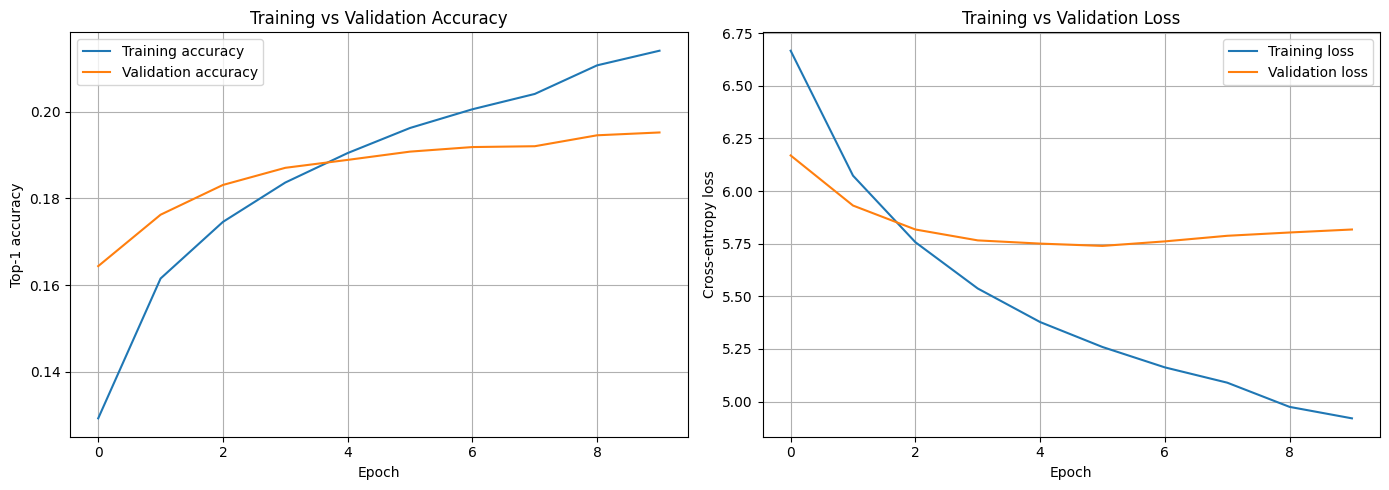

In [20]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Top-1 accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [22]:
# Recreate test examples
X_test, y_test = make_examples(
    test_lines,
    tokenizer,
    SEQ_LEN
)

# Apply the same padding format used for training
X_test = right_pad(X_test)

# Verify right-padding
assert np.all(
    np.diff(X_test == 0, axis=1) >= 0
), "X_test is not correctly right-padded!"

print("Test padding fixed.")
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

Test padding fixed.
X_test shape: (204716, 20)
y_test shape: (204716,)


In [23]:
test_ds = (
    tf.data.Dataset
    .from_tensor_slices((X_test, y_test))
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

print("Test dataset rebuilt successfully.")

Test dataset rebuilt successfully.


In [24]:
best_model = tf.keras.models.load_model(
    "/content/best_lstm_model.keras"
)

results = best_model.evaluate(
    test_ds,
    return_dict=True,
    verbose=1
)

print("\nTEST RESULTS")
for metric, value in results.items():
    print(f"{metric}: {value:.4f}")

test_perplexity = np.exp(
    min(float(results["loss"]), 80)
)

print(f"Test perplexity: {test_perplexity:.2f}")

800/800 ━━━━━━━━━━━━━━━━━━━━ 13s 16ms/step - accuracy: 0.1941 - loss: 5.6482 - top5_accuracy: 0.3672

TEST RESULTS
accuracy: 0.1941
loss: 5.6482
top5_accuracy: 0.3672
Test perplexity: 283.77


In [27]:
import numpy as np

def predict_next_word(text, top_k=5):
    # Convert input text to token IDs
    token_ids = tokenizer.texts_to_sequences([text])[0]

    if len(token_ids) == 0:
        print("No valid tokens found. Try a different sentence.")
        return []

    # Keep only the most recent context words
    token_ids = token_ids[-SEQ_LEN:]

    # Construct RIGHT-padded input manually
    padded = np.zeros((1, SEQ_LEN), dtype=np.int32)
    padded[0, :len(token_ids)] = token_ids

    # Validate the padding mask:
    # True tokens must appear before False padding positions.
    mask = padded[0] != 0

    assert not np.any(np.diff(mask.astype(np.int8)) > 0), (
        "Invalid padding: a real token appears after padding."
    )

    print("Input token IDs:", padded[0])
    print("Padding validation passed.")

    # Predict
    probabilities = best_model(
        padded,
        training=False
    ).numpy()[0]

    # Never recommend the padding token
    probabilities[0] = 0

    # Get top-k predictions
    top_k = min(top_k, len(probabilities) - 1)
    top_ids = np.argsort(probabilities)[-top_k:][::-1]

    predictions = []

    print(f"\nInput: {text}")
    print("\nTop predictions:")

    for idx in top_ids:
        word = index_to_word.get(int(idx), "<unk>")
        probability = float(probabilities[idx])

        predictions.append((word, probability))
        print(f"{word:<20} {probability:.2%}")

    return predictions


predict_next_word("the history of the united states")

Input token IDs: [  2 187   3   2 120 142   0   0   0   0   0   0   0   0   0   0   0   0
   0   0]
Padding validation passed.

Input: the history of the united states

Top predictions:
was                  5.81%
and                  4.83%
<unk>                3.61%
is                   2.88%
were                 1.42%


[('was', 0.05809127539396286),
 ('and', 0.04832607880234718),
 ('<unk>', 0.03614381328225136),
 ('is', 0.028810523450374603),
 ('were', 0.014167360961437225)]

In [30]:

print("LSTM config:", best_model.layers[2].get_config())

LSTM config: {'name': 'dense_2', 'trainable': True, 'dtype': {'module': 'keras', 'class_name': 'DTypePolicy', 'config': {'name': 'float32'}, 'registered_name': None}, 'units': 256, 'activation': 'relu', 'use_bias': True, 'kernel_initializer': {'module': 'keras.initializers', 'class_name': 'GlorotUniform', 'config': {'seed': None}, 'registered_name': None}, 'bias_initializer': {'module': 'keras.initializers', 'class_name': 'Zeros', 'config': {}, 'registered_name': None}, 'kernel_regularizer': {'module': 'keras.regularizers', 'class_name': 'L2', 'config': {'l2': 1e-05}, 'registered_name': None}, 'bias_regularizer': None, 'kernel_constraint': None, 'bias_constraint': None, 'quantization_config': None}


In [31]:
import json
import tensorflow as tf

# Load the best checkpoint if needed
best_model = tf.keras.models.load_model(
    "/content/best_lstm_model.keras"
)

# Save model
best_model.save("/content/best_lstm_model.keras")

# Save the exact tokenizer used during training
with open("/content/tokenizer.json", "w", encoding="utf-8") as f:
    f.write(tokenizer.to_json())

# Save settings required for inference
config = {
    "seq_len": int(SEQ_LEN),
    "vocab_size": int(VOCAB_SIZE),
    "tensorflow_version": tf.__version__
}

with open("/content/model_config.json", "w") as f:
    json.dump(config, f, indent=4)

print("TensorFlow version:", tf.__version__)
print("Export completed!")

TensorFlow version: 2.21.0
Export completed!


In [32]:
from google.colab import files

files.download("/content/best_lstm_model.keras")
files.download("/content/tokenizer.json")
files.download("/content/model_config.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>